# 9주차 (2/2). 평가·분석 — point-adjust 함정, 6종 비교, 유형별, 근거 (CPU)

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from joblib import Parallel, delayed
from scipy.stats import kendalltau

ROOT = Path("..").resolve()
sys.path.append(str(ROOT))
from src import anomaly_adapter as aa
aa.setup()

OUT = ROOT / "results/wk9"
SC = OUT / "scores"
N_JOBS = 6
for f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if f in {x.name for x in font_manager.fontManager.ttflist}:
        plt.rcParams["font.family"] = f
        break
plt.rcParams["axes.unicode_minus"] = False

X, y = aa.load_2016()
prof = pd.read_csv(OUT / "profile.csv", index_col=0)
WIN = prof["slidingWindow"].astype(int).to_dict()
OK = aa.evaluable(y)  # 이상이 1개 이상인 건물
sc = {m: pd.read_parquet(SC / f"{m}.parquet") for m in aa.METHODS if (SC / f"{m}.parquet").exists()}
print("평가 가능 건물:", len(OK), "/ 17 | 이상 0건 제외:", [c for c in X.columns if c not in OK])
print("점수 있는 기법:", list(sc), "| 없는 기법:", [m for m in aa.METHODS if m not in sc])

평가 가능 건물: 17 / 17 | 이상 0건 제외: []
점수 있는 기법: ['CATCH', 'DADA', 'Sub-LOF', 'MatrixProfile', 'IsolationForest', 'LightGBM잔차'] | 없는 기법: []


## 과제 9-2. point-adjust 함정 재현

이상률(평가 건물 평균) = 0.0215
             PA-F1      F1  VUS-PR  AUC-PR  PA-F1 건물간 std  VUS-PR / 이상률
무작위 p=0.5%  0.1061  0.0091  0.0923  0.0224         0.0829        4.3000
무작위 p=1.0%  0.1489  0.0118  0.0926  0.0223         0.1244        4.3143
무작위 p=5.0%  0.2411  0.0295  0.0919  0.0225         0.1285        4.2848

이상 구간 397개, 중앙 길이 7h, 평균 8.1h
{'p=0.5%': 0.039, 'p=1.0%': 0.075, 'p=5.0%': 0.291} ← 구간이 1점 이상 맞혀질 평균 확률


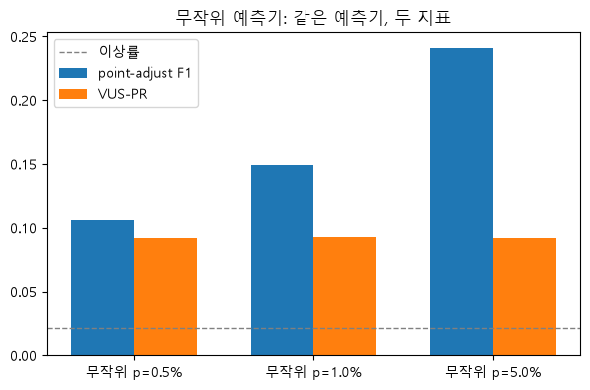

In [2]:
P, N_SEED = [0.005, 0.01, 0.05], 5
RAND_CSV = OUT / "random_predictor_detail.csv"

def rand_eval(c, p, seed):
    rng = np.random.default_rng([seed, int(p * 1000), OK.index(c)])
    pred, score = aa.random_predictor(len(y), p, rng)
    return {"building": c, "p": p, "seed": seed, **aa.evaluate(score, y[c], WIN[c], pred=pred)}

if RAND_CSV.exists():
    rd = pd.read_csv(RAND_CSV)
else:
    t0 = time.time()
    rd = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(rand_eval)(c, p, s) for c in OK for p in P for s in range(N_SEED)))
    rd.to_csv(RAND_CSV, index=False, encoding="utf-8")
    print("평가 %d회, %.0fs" % (len(rd), time.time() - t0))

base = y[OK].to_numpy().mean()
bld = rd.groupby(["p", "building"])[["PA-F1", "F1", "VUS-PR", "AUC-PR"]].mean()  # 건물별 (seed 평균)
t = bld.groupby("p").mean()
t["PA-F1 건물간 std"] = bld["PA-F1"].groupby("p").std()
t.index = [f"무작위 p={p:.1%}" for p in t.index]
t["VUS-PR / 이상률"] = t["VUS-PR"] / base
t.to_csv(OUT / "random_predictor.csv", encoding="utf-8")
print(f"이상률(평가 건물 평균) = {base:.4f}")
print(t.round(4).to_string())

# 왜 부풀려지나: 길이 L 구간을 한 번도 안 찍을 확률은 (1-p)^L  →  구간이 1점 이상 맞혀질 확률
ev = pd.concat([aa.events(y[c]) for c in OK])
print("\n이상 구간 %d개, 중앙 길이 %dh, 평균 %.1fh" % (len(ev), ev.length.median(), ev.length.mean()))
print({f"p={p:.1%}": round(float((1 - (1 - p) ** ev.length).mean()), 3) for p in P}, "← 구간이 1점 이상 맞혀질 평균 확률")

fig, ax = plt.subplots(figsize=(6, 4))
w = 0.35; xs = np.arange(len(t))
ax.bar(xs - w / 2, t["PA-F1"], w, label="point-adjust F1"); ax.bar(xs + w / 2, t["VUS-PR"], w, label="VUS-PR")
ax.axhline(base, color="gray", ls="--", lw=1, label="이상률"); ax.set_xticks(xs); ax.set_xticklabels(t.index)
ax.set_title("무작위 예측기: 같은 예측기, 두 지표"); ax.legend(); plt.tight_layout()
plt.savefig(OUT / "random_predictor.png", dpi=110); plt.show()

### 9-2 ① — 이상 구간 길이에 따른 부풀림 (합성 데이터)

In [3]:
from TSB_AD.evaluation.basic_metrics import basic_metricor
g, n, R, p = basic_metricor(), len(y), 30, 0.01
rows = []
for L in [1, 7, 24, 100, 300]:
    for r in range(R):
        rng = np.random.default_rng([r, L])
        lab = np.zeros(n, int)
        for s0 in rng.choice(np.arange(0, n - L, 2 * L), max(round(base * n / L), 1), replace=False):
            lab[s0:s0 + L] = 1
        pred = (rng.random(n) < p).astype(int)
        rows.append({"구간 길이(h)": L, "실제 이상률": lab.mean(), "PA-F1": g.metric_PointF1PA(lab, pred.astype(float), preds=pred),
                     "F1": g.metric_PointF1(lab, pred.astype(float), preds=pred)})
lenstudy = pd.DataFrame(rows).groupby("구간 길이(h)").mean()
lenstudy["부풀림(PA-F1/F1)"] = lenstudy["PA-F1"] / lenstudy["F1"]
lenstudy.to_csv(OUT / "pa_inflation_by_length.csv", encoding="utf-8")
print(f"무작위 예측기 p={p:.0%}, 합성 라벨 (구간 1개짜리는 이상률이 목표보다 높을 수 있음)")
print(lenstudy.round(3).to_string())

무작위 예측기 p=1%, 합성 라벨 (구간 1개짜리는 이상률이 목표보다 높을 수 있음)
          실제 이상률  PA-F1     F1  부풀림(PA-F1/F1)
구간 길이(h)                                     
1          0.021  0.014  0.014          1.000
7          0.022  0.082  0.012          6.606
24         0.022  0.231  0.013         17.438
100        0.023  0.624  0.015         40.565
300        0.034  0.820  0.014         58.266


### 9-2 ② — 무작위 점수의 VUS-PR이 이상률보다 높은 이유

In [4]:
rs = np.random.default_rng(0).random(len(y))
rows = [{"building": c, "이상률": y[c].mean(), "slidingWindow": WIN[c], "VUS-PR(창=1)": aa.evaluate(rs, y[c], 1)["VUS-PR"],
         "VUS-PR(실제 창)": aa.evaluate(rs, y[c], WIN[c])["VUS-PR"]} for c in ["Hog_parking_Antoinette", "Bull_office_Ella", "Rat_office_Randy"]]
vus_win = pd.DataFrame(rows).set_index("building")
vus_win.to_csv(OUT / "random_vus_window.csv", encoding="utf-8")
print(vus_win.round(4).to_string())

                           이상률  slidingWindow  VUS-PR(창=1)  VUS-PR(실제 창)
building                                                                
Hog_parking_Antoinette  0.0195             24       0.0199        0.0462
Bull_office_Ella        0.0186            140       0.0197        0.0880
Rat_office_Randy        0.0645            168       0.0691        0.2057


## 과제 9-3. 6종 기법 비교 — PA-F1 vs VUS-PR

                  PA-F1  VUS-PR  AUC-PR  PA-F1 순위  VUS-PR 순위  순위 차이  무작위(p=1%) 대비 VUS-PR(배)  건물별 VUS-PR 1위 횟수        라벨 사용
method                                                                                                                    
CATCH            0.4925  0.3383  0.1597         2          2      0                  3.6548                 4           없음
DADA             0.4057  0.2741  0.1164         3          4     -1                  2.9614                 3           없음
Sub-LOF          0.2576  0.3132  0.0873         4          3      1                  3.3836                 3           없음
MatrixProfile    0.1645  0.1564  0.0414         6          6      0                  1.6892                 1           없음
IsolationForest  0.2154  0.2179  0.0937         5          5      0                  2.3545                 3           없음
LightGBM잔차       0.5299  0.3990  0.2597         1          1      0                  4.3104                 3  지도(정상구간 선별)

(참고) 무작위 p=1%: 

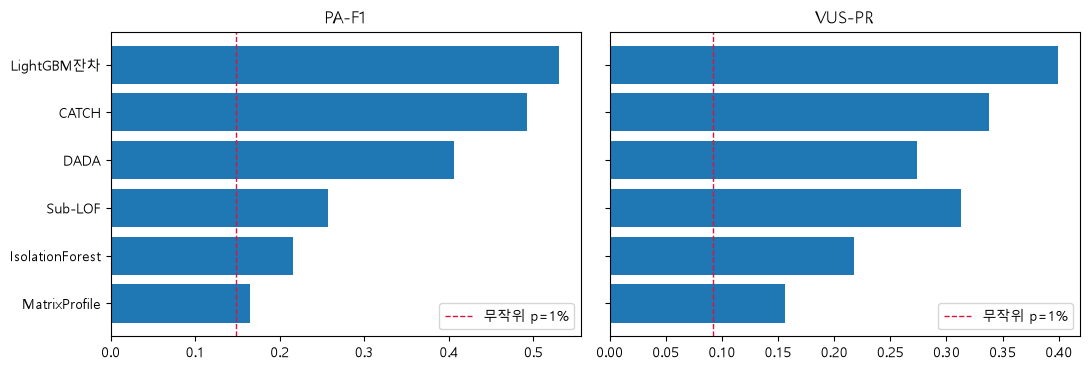

In [5]:
PB_CSV = OUT / "per_building_metrics.csv"

def eval_one(m, c):
    return {"method": m, "building": c, **aa.evaluate(sc[m][c], y[c], WIN[c])}

if PB_CSV.exists():
    pb = pd.read_csv(PB_CSV)
else:
    t0 = time.time()
    pb = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(eval_one)(m, c) for m in sc for c in OK))
    pb.to_csv(PB_CSV, index=False, encoding="utf-8")
    print("평가 %d회, %.0fs" % (len(pb), time.time() - t0))

summ = pb.groupby("method")[["PA-F1", "VUS-PR", "AUC-PR"]].mean().reindex([m for m in aa.METHODS if m in sc])
summ["PA-F1 순위"] = summ["PA-F1"].rank(ascending=False).astype(int)
summ["VUS-PR 순위"] = summ["VUS-PR"].rank(ascending=False).astype(int)
summ["순위 차이"] = summ["PA-F1 순위"] - summ["VUS-PR 순위"]
r1 = rd[rd.p == 0.01]
summ["무작위(p=1%) 대비 VUS-PR(배)"] = summ["VUS-PR"] / r1["VUS-PR"].mean()
summ["건물별 VUS-PR 1위 횟수"] = (pb.pivot(index="building", columns="method", values="VUS-PR").idxmax(axis=1)
                              .value_counts().reindex(summ.index).fillna(0).astype(int))
summ["라벨 사용"] = ["지도(정상구간 선별)" if m == "LightGBM잔차" else "없음" for m in summ.index]
tau = kendalltau(summ["PA-F1"], summ["VUS-PR"])
print(summ.round(4).to_string())
print(f"\n(참고) 무작위 p=1%: PA-F1 {r1['PA-F1'].mean():.3f} / VUS-PR {r1['VUS-PR'].mean():.3f}")
print(f"두 지표 순위의 Kendall τ = {tau.statistic:.2f} (1.0이면 순위 동일)")
summ.to_csv(OUT / "method_comparison.csv", encoding="utf-8")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col in zip(axes, ["PA-F1", "VUS-PR"]):
    s = summ[col].sort_values()
    ax.barh(s.index, s.values)
    ax.axvline(r1[col].mean(), color="crimson", ls="--", lw=1, label="무작위 p=1%")
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "method_comparison.png", dpi=110); plt.show()

In [6]:
from scipy.stats import wilcoxon
vp = pb.pivot(index="building", columns="method", values="VUS-PR")[summ.index]
spread = pd.DataFrame({"평균": vp.mean(), "중앙값": vp.median(), "건물간 std": vp.std()})
spread["CATCH와 차이 p(Wilcoxon)"] = {m: (np.nan if m == "CATCH" else wilcoxon(vp["CATCH"], vp[m]).pvalue) for m in vp}
spread.to_csv(OUT / "vuspr_spread.csv", encoding="utf-8")
print(spread.round(4).to_string())

                     평균     중앙값  건물간 std  CATCH와 차이 p(Wilcoxon)
method                                                         
CATCH            0.3383  0.2640   0.2674                    NaN
DADA             0.2741  0.1678   0.2920                 0.0569
Sub-LOF          0.3132  0.3418   0.1870                 0.9265
MatrixProfile    0.1564  0.1059   0.1265                 0.0013
IsolationForest  0.2179  0.1082   0.2542                 0.0110
LightGBM잔차       0.3990  0.4065   0.2839                 0.3529


In [7]:
# 12주차 누적표용 한 줄씩: VUS-PR · 시간 · GPU 필요 · 라벨 사용
GPU_NEED = {"CATCH": "학습 GPU", "DADA": "추론 GPU", "Sub-LOF": "불필요", "MatrixProfile": "불필요",
            "IsolationForest": "불필요", "LightGBM잔차": "불필요(4주차)"}
rl = pd.read_csv(OUT / "run_log.csv") if (OUT / "run_log.csv").exists() else pd.DataFrame(columns=["method", "secs", "device"])
cum = (summ[["VUS-PR", "PA-F1"]].join(rl.groupby("method")["secs"].sum().rename("17건물 합계(s)"))
       .join(rl.groupby("method")["device"].first().rename("측정 장치")))
cum["GPU 필요"] = pd.Series(GPU_NEED)
cum["라벨 사용"] = summ["라벨 사용"]
cum.to_csv(OUT / "cumulative_row.csv", encoding="utf-8")
print(cum.round(3).to_string())

                 VUS-PR  PA-F1  17건물 합계(s) 측정 장치    GPU 필요        라벨 사용
method                                                                 
CATCH             0.338  0.493      72.796   GPU    학습 GPU           없음
DADA              0.274  0.406       0.495   GPU    추론 GPU           없음
Sub-LOF           0.313  0.258       4.337   CPU       불필요           없음
MatrixProfile     0.156  0.165      49.312   CPU       불필요           없음
IsolationForest   0.218  0.215       1.538   CPU       불필요           없음
LightGBM잔차        0.399  0.530         NaN   NaN  불필요(4주차)  지도(정상구간 선별)


## 과제 9-4. 이상 유형별 분석

In [8]:
ev = pd.concat([aa.events(y[c]).assign(building=c) for c in OK], ignore_index=True)
print(ev["length"].describe().round(1).to_string())
print("\n길이 분위수:", ev["length"].quantile([.25, .5, .75, .9]).to_dict())
print("길이 1h:", int((ev.length == 1).sum()), "| 2~24h:", int(ev.length.between(2, 24).sum()), "| 24h 초과:", int((ev.length > 24).sum()))

count    397.0
mean       8.1
std        9.0
min        1.0
25%        3.0
50%        7.0
75%       10.0
max       72.0

길이 분위수: {0.25: 3.0, 0.5: 7.0, 0.75: 10.0, 0.9: 17.400000000000034}
길이 1h: 63 | 2~24h: 318 | 24h 초과: 16


유형별 이벤트 수: {'점': 63, '짧은 구간': 318, '긴 구간': 16}
type                 점  짧은 구간   긴 구간
method                              
CATCH            0.190  0.516  0.500
DADA             0.127  0.399  0.375
Sub-LOF          0.143  0.189  0.312
MatrixProfile    0.048  0.082  0.062
IsolationForest  0.000  0.167  0.375
LightGBM잔차       0.032  0.550  0.812
(무작위 기대)         0.016  0.184  0.665


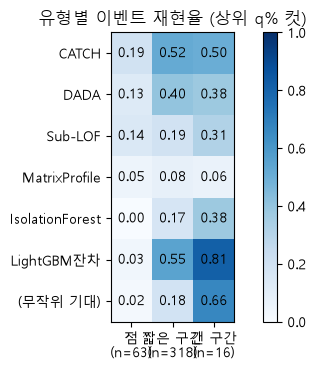

In [9]:
BINS = (1, 24)  # 점 = 1h 이하 / 짧은 구간 = 2~24h / 긴 구간 = 24h 초과  ← 위 분포를 보고 필요하면 수정
rows = []
for m in sc:
    for c in OK:
        e = aa.event_recall_by_type(sc[m][c], y[c], BINS)
        rows.append(e.assign(method=m, building=c, q=y[c].mean()))
ev_all = pd.concat(rows, ignore_index=True)
ev_all["무작위 기대"] = 1 - (1 - ev_all["q"]) ** ev_all["length"]

first = ev_all[ev_all.method == ev_all.method.iloc[0]]
rec = ev_all.groupby(["method", "type"], observed=True)["hit"].mean().unstack().reindex([m for m in aa.METHODS if m in sc])
rec.loc["(무작위 기대)"] = first.groupby("type", observed=True)["무작위 기대"].mean()
cnt = first.groupby("type", observed=True).size()
print("유형별 이벤트 수:", cnt.to_dict())
print(rec.round(3).to_string())
rec.to_csv(OUT / "type_recall.csv", encoding="utf-8")

fig, ax = plt.subplots(figsize=(6, 3.8))
im = ax.imshow(rec.to_numpy(float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(rec.shape[1])); ax.set_xticklabels([f"{c}\n(n={cnt[c]})" for c in rec.columns])
ax.set_yticks(range(len(rec))); ax.set_yticklabels(rec.index)
for i in range(rec.shape[0]):
    for j in range(rec.shape[1]):
        ax.text(j, i, f"{rec.iat[i, j]:.2f}", ha="center", va="center")
ax.set_title("유형별 이벤트 재현율 (상위 q% 컷)"); plt.colorbar(im); plt.tight_layout()
plt.savefig(OUT / "type_recall.png", dpi=110); plt.show()

## 과제 9-5. 이상 근거 제시 — 3건

                                       0                    1                    2
building               Bull_office_Sally     Bull_office_Ella      Rat_office_Lora
timestamp            2016-10-15 22:00:00  2016-10-15 22:00:00  2016-10-10 14:00:00
라벨                                     1                    1                    1
실제값                               2383.0               1842.0               237.69
같은 요일·시각 정상 중앙값                     69.0               76.667               741.88
배수                                34.536               24.026                 0.32
MP 최근접 구간 시작         2016-06-28 05:00:00  2016-06-30 09:00:00  2016-11-10 03:00:00
MP 거리                             10.045                8.823                2.191
CATCH 백분위                          0.948                0.959                0.983
DADA 백분위                           0.971                0.975                0.956
Sub-LOF 백분위                        0.786                0.767                0.774
Matr

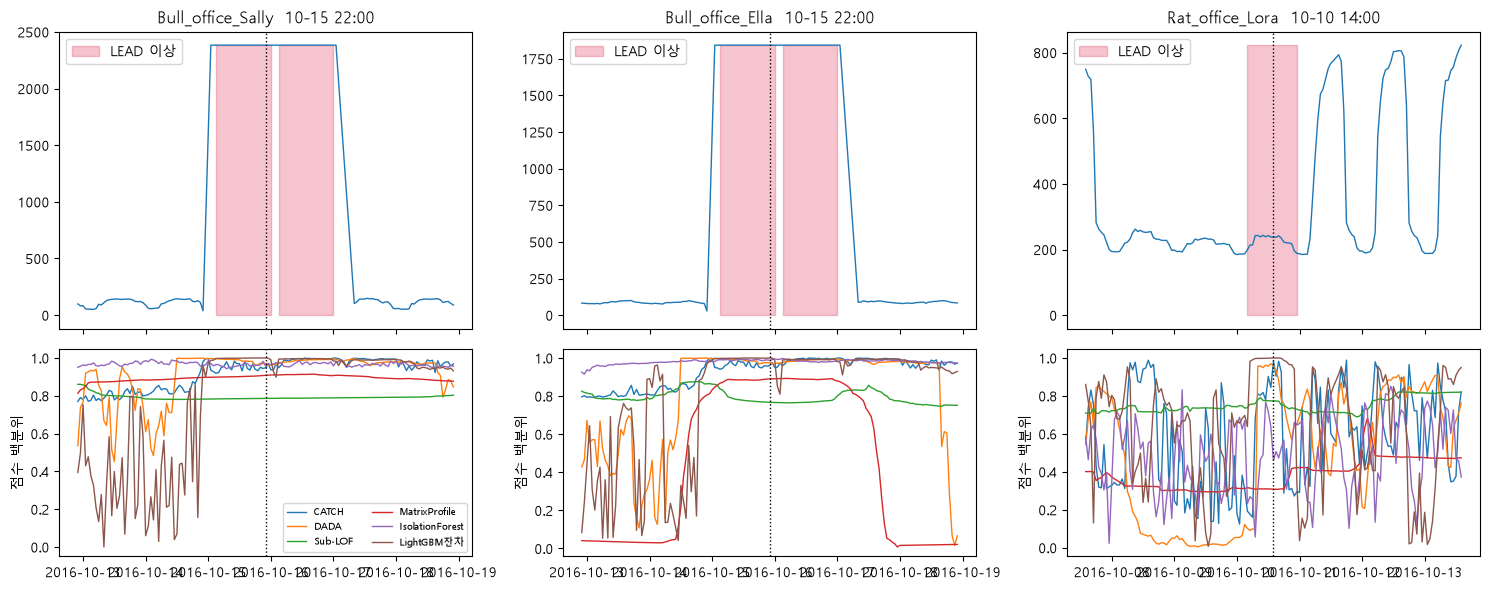

In [10]:
import stumpy

EVENTS = [("Bull_office_Sally", "2016-10-15 22:00"), ("Bull_office_Ella", "2016-10-15 22:00"), ("Rat_office_Lora", "2016-10-10 14:00")]
pct = {m: sc[m].rank(pct=True) for m in sc}  # 건물 안 점수 백분위 (1.0 = 가장 이상)
rows = []
for c, ts in EVENTS:
    ts = pd.Timestamp(ts)
    normal = X[c][~y[c]]
    same = normal[(normal.index.dayofweek == ts.dayofweek) & (normal.index.hour == ts.hour)]  # 같은 요일·시각의 정상 시점
    z = (X[c] - X[c].min()) / (X[c].max() - X[c].min())
    mp = stumpy.stump(z.to_numpy(), m=WIN[c])
    i = int(np.clip(X.index.get_loc(ts) - WIN[c] // 2, 0, len(mp) - 1))  # MatrixProfile 점수와 같은 정렬(창 중앙)
    rows.append({"building": c, "timestamp": ts, "라벨": int(y.at[ts, c]), "실제값": X.at[ts, c],
                 "같은 요일·시각 정상 중앙값": same.median(), "배수": X.at[ts, c] / max(same.median(), 1e-6),
                 "MP 최근접 구간 시작": X.index[int(mp[i, 1])], "MP 거리": mp[i, 0],
                 **{f"{m} 백분위": pct[m].at[ts, c] for m in sc}})
expl = pd.DataFrame(rows)
expl.to_csv(OUT / "explain_events.csv", index=False, encoding="utf-8")
print(expl.round(3).T.to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex="col", gridspec_kw={"height_ratios": [2, 1.4]})
for j, (c, ts) in enumerate(EVENTS):
    ts = pd.Timestamp(ts); sl = slice(ts - pd.Timedelta(hours=72), ts + pd.Timedelta(hours=72))
    a, b = axes[0, j], axes[1, j]
    a.plot(X.loc[sl, c], lw=1)
    a.fill_between(X.loc[sl].index, 0, X.loc[sl, c].max(), where=y.loc[sl, c], alpha=.25, color="crimson", label="LEAD 이상")
    a.axvline(ts, color="k", ls=":", lw=1); a.set_title(f"{c}  {ts:%m-%d %H:%M}"); a.legend(loc="upper left")
    for m in sc:
        b.plot(pct[m].loc[sl, c], lw=1, label=m)
    b.axvline(ts, color="k", ls=":", lw=1); b.set_ylabel("점수 백분위")
axes[1, 0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(OUT / "explain_events.png", dpi=110); plt.show()

## 결과 점검

In [11]:
import stumpy

def mp_score(c, m, norm):
    z = ((X[c] - X[c].min()) / (X[c].max() - X[c].min())).to_numpy()
    prof = stumpy.stump(z, m=m, normalize=norm)[:, 0].astype(float)
    prof = np.where(np.isfinite(prof), prof, 0.0)
    s = np.full(len(z), prof.min())
    s[m // 2:m // 2 + len(prof)] = prof  # TSB-AD MatrixProfile 과 같은 정렬·패딩
    return s

MP_CFG = {"z-정규화 · 창=건물별(기존)": (None, True), "z-정규화 · 창=24": (24, True), "z-정규화 · 창=168": (168, True),
          "원값 거리 · 창=24": (24, False), "원값 거리 · 창=168": (168, False)}
def mp_eval(name, c):
    m, norm = MP_CFG[name]
    return {"설정": name, "building": c, **aa.evaluate(mp_score(c, m or WIN[c], norm), y[c], WIN[c])}  # 평가 창은 모두 기존 WIN 으로 고정

mp = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(mp_eval)(n, c) for n in MP_CFG for c in OK))
mp_t = mp.groupby("설정")[["PA-F1", "VUS-PR", "AUC-PR"]].mean().reindex(list(MP_CFG))
mp_t["무작위(p=1%) 대비 VUS-PR(배)"] = mp_t["VUS-PR"] / r1["VUS-PR"].mean()
mp_t.to_csv(OUT / "check_matrixprofile.csv", encoding="utf-8")
print(mp_t.round(4).to_string())
print(f"(참고) 6종 표의 Matrix Profile: VUS-PR {summ.loc['MatrixProfile', 'VUS-PR']:.4f} · Sub-LOF {summ.loc['Sub-LOF', 'VUS-PR']:.4f} · 무작위 p=1% {r1['VUS-PR'].mean():.4f}")

                    PA-F1  VUS-PR  AUC-PR  무작위(p=1%) 대비 VUS-PR(배)
설정                                                               
z-정규화 · 창=건물별(기존)  0.1645  0.1564  0.0414                  1.6892
z-정규화 · 창=24       0.2102  0.1684  0.0551                  1.8192
z-정규화 · 창=168      0.1913  0.1822  0.0593                  1.9685
원값 거리 · 창=24       0.3515  0.3931  0.1225                  4.2465
원값 거리 · 창=168      0.2456  0.2533  0.1167                  2.7367
(참고) 6종 표의 Matrix Profile: VUS-PR 0.1564 · Sub-LOF 0.3132 · 무작위 p=1% 0.0926


In [12]:
rows = []
for c in X.columns:
    v = pd.Series(X[c].to_numpy())
    flat = (v.groupby((v.diff() != 0).cumsum()).transform("size") >= 12).to_numpy()  # 12h 이상 같은 값이 이어진 시점
    lab = y[c].to_numpy()
    rows.append({"building": c, "고정값 시점": int(flat.sum()), "라벨 시점": int(lab.sum()), "라벨∩고정값": int((flat & lab).sum())})
fl = pd.DataFrame(rows).set_index("building")
fl.loc["합계"] = fl.sum()
fl["라벨 중 고정값 비율"] = fl["라벨∩고정값"] / fl["라벨 시점"]
fl["고정값 중 라벨 비율"] = fl["라벨∩고정값"] / fl["고정값 시점"].replace(0, np.nan)
fl.to_csv(OUT / "check_label_flat.csv", encoding="utf-8")
print(fl.round(3).to_string())

                        고정값 시점  라벨 시점  라벨∩고정값  라벨 중 고정값 비율  고정값 중 라벨 비율
building                                                               
Hog_parking_Antoinette     119    171       0        0.000        0.000
Fox_office_Vicki             0    166       0        0.000          NaN
Fox_office_Joy               0    123       0        0.000          NaN
Hog_services_Marshall       50    101      49        0.485        0.980
Bull_office_Ella           122    163     110        0.675        0.902
Fox_education_Elvira         0    105       0        0.000          NaN
Bull_office_Sally          122    208     110        0.529        0.902
Fox_education_Charles        0    302       0        0.000          NaN
Bear_education_Chad          0    250       0        0.000          NaN
Rat_office_Lora              0    258       0        0.000          NaN
Rat_office_Adele             0     92       0        0.000          NaN
Rat_assembly_Kelley          0    246       0        0.000      

In [13]:
gm = basic_metricor()
orc = pd.DataFrame([{"building": c, "seed": s, "PA-F1(최적 임계값)": gm.metric_PointF1PA(y[c].astype(int).to_numpy(), np.random.default_rng([s, i]).random(len(y)), preds=None)}
                    for i, c in enumerate(OK) for s in range(5)])
cmp_ = pd.DataFrame({"PA-F1": summ["PA-F1"]})
cmp_.loc["(무작위 · 최적 임계값)"] = orc["PA-F1(최적 임계값)"].mean()
cmp_.loc["(무작위 · p=1% 고정)"] = r1["PA-F1"].mean()
cmp_.loc["(무작위 · p=5% 고정)"] = rd[rd.p == 0.05]["PA-F1"].mean()
cmp_.to_csv(OUT / "check_random_oracle.csv", encoding="utf-8")
print(cmp_.round(4).to_string())

                  PA-F1
method                 
CATCH            0.4925
DADA             0.4057
Sub-LOF          0.2576
MatrixProfile    0.1645
IsolationForest  0.2154
LightGBM잔차       0.5299
(무작위 · 최적 임계값)   0.2965
(무작위 · p=1% 고정)  0.1489
(무작위 · p=5% 고정)  0.2411
